# Day 2 · 06 — Demo: uncertainty, proper scoring rules and conformal prediction (20 min)

A lecture segment with a live demo. Three ways to get an 80 % / 95 % interval for the same data:

1. **Model-based quantiles**: NHITS trained with a multi-quantile loss (`MQLoss`).
2. **Conformal intervals** around a point model: `mlforecast` LightGBM with `PredictionIntervals`
   (split conformal on rolling windows of the training data).
3. **Conformal intervals** around a local model: `statsforecast` AutoETS with `ConformalIntervals`.

And two ways to judge them:

* **Calibration**: does the 80 % interval contain the truth 80 % of the time?
* **Proper scoring rules**: scaled CRPS (approximated by the average quantile loss) and the interval
  (Winkler) score. Proper means you cannot improve your expected score by reporting something other than your
  true belief, so narrow-but-wrong intervals are punished.

In [1]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import bootcamp as bc

warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)
palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.prop_cycle": plt.cycler(color=palette)})

LEVELS = [80, 95]

panel = bc.load_panel()
train, test = bc.split(panel)
Y_train, Y_test = bc.to_nixtla(train), bc.to_nixtla(test)

/home/user/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Intuition: calibration, sharpness and honest scores

![Pinball loss and interval quality](slides/img/pinball.png)

* A weather forecaster who says "30 % chance of rain" should see rain on about 30 % of those days: that is
  **calibration**. "Between 0 and 100 mm" is always right and useless: among calibrated forecasts, prefer the
  **sharpest**.
* The **pinball loss** is what makes a model produce a quantile: for the 90 % quantile, being 1 unit too low
  costs 9 times as much as being 1 unit too high, so the best answer sits high.
* **Conformal** is "be as wrong as you were before": collect the model's misses on held-out weeks and put
  that much around every new forecast. It works for any model, as long as the future looks like the past you
  calibrated on.

![Conformal in two steps](slides/img/conformal.png)

## 1. NHITS with a multi-quantile loss

In [2]:
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MQLoss
from neuralforecast.models import NHITS

nf = NeuralForecast(models=[NHITS(h=bc.H, input_size=4 * bc.H, loss=MQLoss(level=LEVELS), scaler_type="robust",
                                  max_steps=bc.MAX_STEPS, random_seed=bc.RANDOM_SEED, **bc.trainer_kwargs())],
                    freq=bc.FREQ)
nf.fit(df=Y_train, val_size=bc.H)
nh = nf.predict()
nh.columns = [c.replace("NHITS", "NHITS_MQ") for c in nh.columns]
nh = nh.rename(columns={"NHITS_MQ-median": "NHITS_MQ"})

2026-10-27 21:54:15,473	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-10-27 21:54:15,935	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


## 2. LightGBM + conformal intervals

In [3]:
import lightgbm as lgb
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean
from mlforecast.target_transforms import LocalStandardScaler
from mlforecast.utils import PredictionIntervals

mlf = MLForecast(
    models={"LightGBM_conf": lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=63,
                                               random_state=bc.RANDOM_SEED, verbosity=-1)},
    freq=bc.FREQ, lags=[1, 2, 4, 13], lag_transforms={1: [RollingMean(4), RollingMean(13)]},
    date_features=["month", "week"], target_transforms=[LocalStandardScaler()],
)
mlf.fit(Y_train, prediction_intervals=PredictionIntervals(n_windows=3, h=bc.H))
lg = mlf.predict(h=bc.H, level=LEVELS)

## 3. AutoETS + conformal intervals

In [4]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS
from statsforecast.utils import ConformalIntervals

sf = StatsForecast(models=[AutoETS(season_length=1, alias="ETS_conf",
                                   prediction_intervals=ConformalIntervals(n_windows=3, h=bc.H))],
                   freq=bc.FREQ, n_jobs=-1)
et = sf.forecast(df=Y_train, h=bc.H, level=LEVELS)

fc = nh.merge(lg, on=["unique_id", "ds"]).merge(et, on=["unique_id", "ds"]).merge(Y_test, on=["unique_id", "ds"])
MODELS = ["NHITS_MQ", "LightGBM_conf", "ETS_conf"]

## 4. Score the intervals

For an interval [l, u] at level 1 − α the **interval score** is
`(u − l) + (2/α)(l − y)·1[y < l] + (2/α)(y − u)·1[y > u]`: width plus a penalty for every miss.
We scale it, like RMSSE, by each series' in-sample seasonal-naive MAE so that series are comparable.

**Scaled CRPS** is approximated from the quantiles we have (the 2.5, 10, 50, 90 and 97.5 % quantiles) by the
average pinball loss, scaled the same way.

In [5]:
def scale_by_series(train_pd: pd.DataFrame) -> pd.Series:
    def s(g):
        d = np.abs(g["y"].values[bc.SEASON:] - g["y"].values[:-bc.SEASON])
        return d.mean() if len(d) else np.nan
    return train_pd.groupby("unique_id").apply(s).replace(0, np.nan).rename("scale")

scale = scale_by_series(Y_train)
fc = fc.merge(scale, left_on="unique_id", right_index=True)

def pinball(y, q, tau):
    return np.maximum(tau * (y - q), (tau - 1) * (y - q))

rows = []
for m in MODELS:
    r = {"model": m}
    quantiles = {0.5: fc[m]}
    for lvl in LEVELS:
        lo, hi = fc[f"{m}-lo-{lvl}"].clip(lower=0), fc[f"{m}-hi-{lvl}"]
        a = 1 - lvl / 100
        inside = (fc.y >= lo) & (fc.y <= hi)
        width = hi - lo
        iscore = width + (2 / a) * (lo - fc.y).clip(lower=0) + (2 / a) * (fc.y - hi).clip(lower=0)
        r[f"coverage_{lvl}"] = inside.mean()
        r[f"scaled_width_{lvl}"] = (width / fc.scale).median()
        r[f"scaled_interval_score_{lvl}"] = (iscore / fc.scale).groupby(fc.unique_id).mean().mean()
        quantiles[a / 2], quantiles[1 - a / 2] = lo, hi
    crps = sum(pinball(fc.y, q, tau) for tau, q in quantiles.items()) * 2 / len(quantiles)
    r["scaled_crps"] = (crps / fc.scale).groupby(fc.unique_id).mean().mean()
    rows.append(r)
uq = pd.DataFrame(rows).set_index("model")
uq.round(3)

,coverage_80,scaled_width_80,scaled_interval_score_80,coverage_95,scaled_width_95,scaled_interval_score_95,scaled_crps
model,,,,,,,
NHITS_MQ,0.853,2.487,15.632,0.972,4.582,32.990,1.473
LightGBM_conf,0.674,2.216,26.476,0.744,2.640,95.551,2.653
ETS_conf,0.683,2.084,25.696,0.745,2.520,92.056,2.556


### Reading the result

![Coverage vs promise](slides/img/res_lab06.png)

* **NHITS with a quantile loss** slightly over-covers (≈ 85 % for a promised 80 %) and has the best scaled CRPS
  (≈ 1.47 vs ≈ 2.6): it learned **per-item** widths.
* **Conformal** intervals under-cover in the test quarter (≈ 67–68 % instead of 80 %). The guarantee holds when
  the future is exchangeable with the calibration windows; April to July brought promotions and shifts those
  windows had not seen, and one width is shared by fast and slow items.
* Fixes: calibrate per class, on recent windows, or conformalise the quantile model (CQR).

*Reference run: 2,000 series, laptop CPU, 500 steps. Your numbers will differ a little; the reading should not.*

### Calibration by velocity class

Average coverage can hide a model that is too wide on fast movers and too narrow on slow movers.

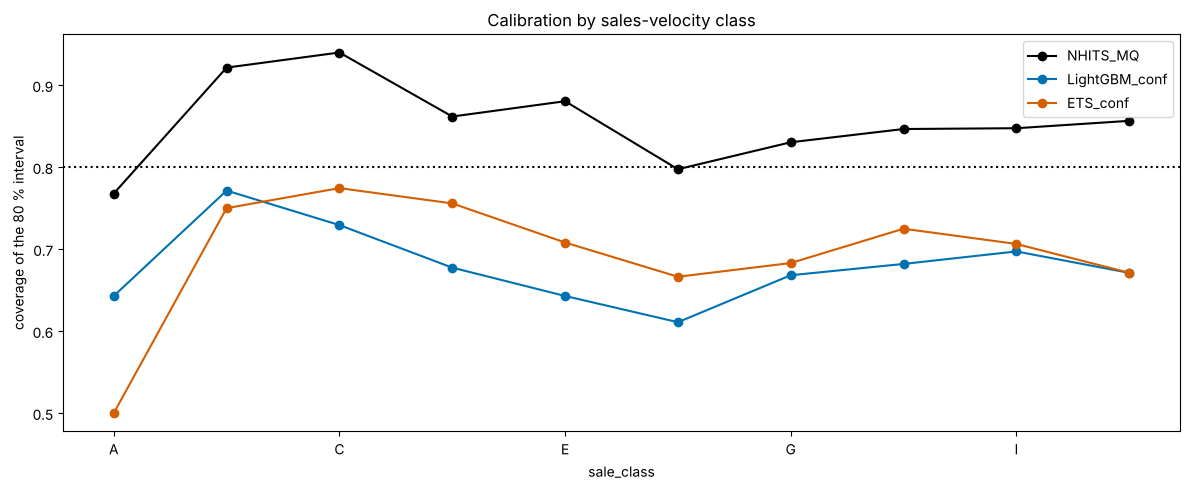

In [6]:
info = bc.series_info(panel).select("unique_id", "sale_class").to_pandas()
cov = fc.merge(info, on="unique_id")
for m in MODELS:
    cov[m] = (cov.y >= cov[f"{m}-lo-80"].clip(lower=0)) & (cov.y <= cov[f"{m}-hi-80"])
ax = cov.groupby("sale_class")[MODELS].mean().plot(marker="o")
ax.axhline(0.8, color="black", ls=":")
ax.set_ylabel("coverage of the 80 % interval")
ax.set_title("Calibration by sales-velocity class")
plt.tight_layout()

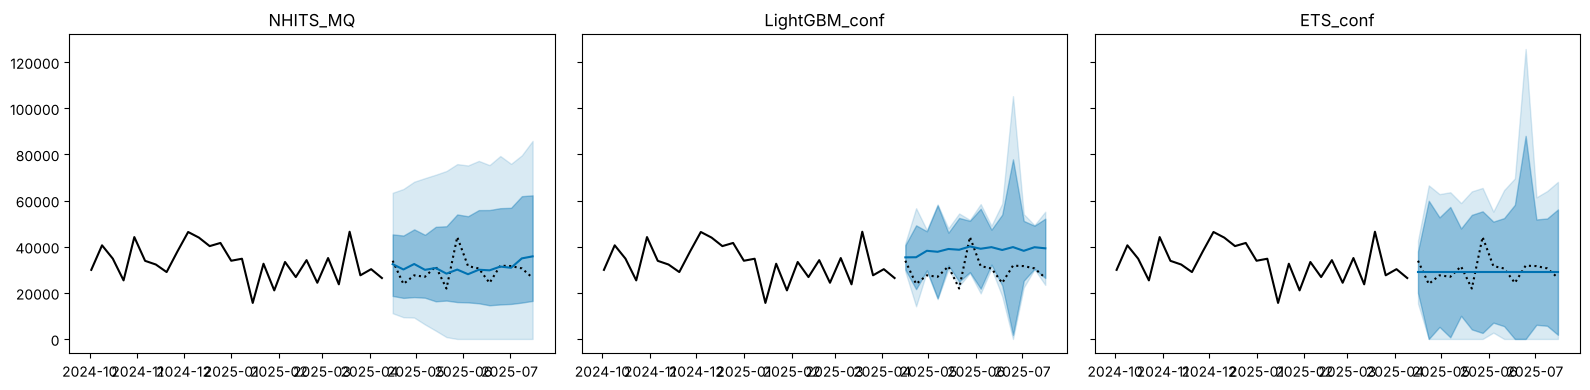

In [7]:
uid = info[info.sale_class == "D"].unique_id.iloc[0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
h = Y_train[(Y_train.unique_id == uid) & (Y_train.ds >= "2024-10-01")]
for ax, m in zip(axes, MODELS):
    f = fc[fc.unique_id == uid]
    ax.plot(h.ds, h.y, color="black")
    ax.plot(f.ds, f.y, color="black", ls=":")
    ax.plot(f.ds, f[m], color=palette[1])
    for lvl, alpha in zip(LEVELS, [0.35, 0.15]):
        ax.fill_between(f.ds, f[f"{m}-lo-{lvl}"].clip(lower=0), f[f"{m}-hi-{lvl}"], color=palette[1], alpha=alpha)
    ax.set_title(m)
plt.tight_layout()

The point forecasts go on the leaderboard too: the NHITS median and the LightGBM mean (the ETS point forecast
is the same AutoETS that notebook 00 already recorded).

In [8]:
POINT = ["NHITS_MQ", "LightGBM_conf"]
bc.save_forecasts(fc[["unique_id", "ds"] + POINT], "06_uncertainty")
bc.record(fc[["unique_id", "ds"] + POINT], test, train, lab="06 uncertainty")
uq.to_csv(bc.RESULTS_DIR / "uncertainty_scores.csv")

## Take-aways

* **Coverage alone is not a score**: a 0-to-infinity interval has 100 % coverage. Use a proper score
  (interval score, CRPS) and look at coverage as a diagnostic.
* **Conformal** gives finite-sample marginal coverage under exchangeability, around any point model, for the
  price of a few extra rolling fits. It does not give coverage per series or per promo week.
* **Quantile losses** make the network learn shape (e.g. right skew on promo weeks) but have no coverage
  guarantee; you can still conformalise them afterwards.